<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-01/nonlinearity-and-universal-approximation.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
**Author:** Marcin Płodzień
<hr/>
# Nonlinear activations in neural networks

A neural network is a composition of layers $\mathbf h \mapsto \sigma(W\mathbf h+\mathbf b)$. This notebook shows, with three small
experiments, why the activation $\sigma$ must be **nonlinear**, and gives the intuition behind the **universal approximation theorem**:

1. without $\sigma$, any number of layers collapses into a single linear map;
2. with ReLU, three neurons build a "hat", and sums of hats approximate any continuous function;
3. a sigmoid with a large weight becomes a step, and differences of steps build any function bar by bar.

It produces the figures of the corresponding slides. Everything runs on the CPU.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"
import numpy as np
import matplotlib.pyplot as plt
import jax, jax.numpy as jnp, optax

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
savefig = lambda fig, name: fig.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")
NUMBERS = {}

## 1. Without a nonlinearity, depth does nothing

Two linear layers are one linear layer:
$$
W_2\,(W_1\mathbf x+\mathbf b_1)+\mathbf b_2 \;=\; \underbrace{W_2W_1}_{W}\,\mathbf x+\underbrace{W_2\mathbf b_1+\mathbf b_2}_{\mathbf b}.
$$
By induction, any stack of linear layers is a single affine map, so a deep "network" without activations can only draw a **straight**
decision boundary. We train the same architecture (3 hidden layers of 16 neurons) on the two-moons data twice: once with the identity
as activation, once with ReLU.

accuracy on the training data:  identity activation 0.870,  ReLU 1.000


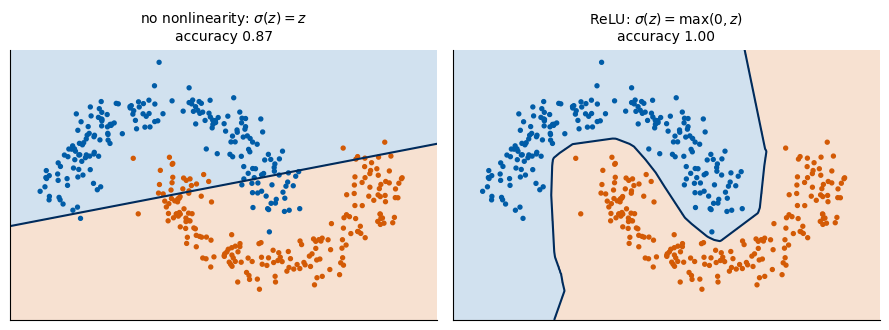

In [2]:
def two_moons(key, n=400, noise=0.12):
    k1, k2 = jax.random.split(key)
    t = jax.random.uniform(k1, (n,)) * jnp.pi
    half = jnp.arange(n) % 2
    x = jnp.where(half[:, None] == 0, jnp.stack([jnp.cos(t), jnp.sin(t)], 1), jnp.stack([1 - jnp.cos(t), 0.5 - jnp.sin(t)], 1))
    return x + noise * jax.random.normal(k2, x.shape), half

X, y = two_moons(jax.random.PRNGKey(0))

def init(key, sizes):
    keys = jax.random.split(key, len(sizes) - 1)
    return [(jax.random.normal(k, (a, b)) / jnp.sqrt(a), jnp.zeros(b)) for k, a, b in zip(keys, sizes[:-1], sizes[1:])]

def forward(params, x, act):
    for W, b in params[:-1]:
        x = act(x @ W + b)
    W, b = params[-1]
    return (x @ W + b)[:, 0]                      # logit

def train(act, steps=3000, seed=1):
    params = init(jax.random.PRNGKey(seed), [2, 16, 16, 16, 1])
    opt = optax.adam(1e-2); state = opt.init(params)
    loss = lambda p: optax.sigmoid_binary_cross_entropy(forward(p, X, act), y).mean()
    @jax.jit
    def step(p, s):
        l, g = jax.value_and_grad(loss)(p)
        u, s = opt.update(g, s); return optax.apply_updates(p, u), s, l
    for _ in range(steps):
        params, state, l = step(params, state)
    acc = float(((forward(params, X, act) > 0) == y).mean())
    return params, acc

identity = lambda z: z
p_lin, acc_lin = train(identity)
p_relu, acc_relu = train(jax.nn.relu)
print(f"accuracy on the training data:  identity activation {acc_lin:.3f},  ReLU {acc_relu:.3f}")
NUMBERS.update(acc_linear=round(acc_lin, 3), acc_relu=round(acc_relu, 3))

gx, gy = np.meshgrid(np.linspace(-1.5, 2.5, 300), np.linspace(-1.0, 1.5, 300))
grid = jnp.asarray(np.stack([gx.ravel(), gy.ravel()], 1), jnp.float32)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for a, (p, act, name, acc) in zip(ax, [(p_lin, identity, "no nonlinearity: $\\sigma(z)=z$", acc_lin),
                                       (p_relu, jax.nn.relu, "ReLU: $\\sigma(z)=\\max(0,z)$", acc_relu)]):
    z = np.asarray(forward(p, grid, act)).reshape(gx.shape)
    a.contourf(gx, gy, z > 0, levels=[-0.5, 0.5, 1.5], colors=[UJBlue, DSOrange], alpha=0.18)
    a.contour(gx, gy, z, levels=[0], colors=UJNavy, linewidths=1.5)
    a.scatter(X[:, 0], X[:, 1], c=[UJBlue if v == 0 else DSOrange for v in np.asarray(y)], s=8)
    a.set_title(f"{name}\naccuracy {acc:.2f}", fontsize=10); a.set_xticks([]); a.set_yticks([])
fig.tight_layout(); savefig(fig, "gen_uat_linear_collapse.png"); plt.show()

## 2. A function from ReLU pieces

Three ReLU neurons make a **hat** of width $2h$ centred at $c$:
$$
\Lambda_c(x) = \frac{1}{h}\Big[\mathrm{ReLU}(x-c+h) - 2\,\mathrm{ReLU}(x-c) + \mathrm{ReLU}(x-c-h)\Big].
$$
Place hats on a grid $c_k = kh$ and give each the height $g(c_k)$: the sum $\sum_k g(c_k)\Lambda_{c_k}(x)$ is the piecewise-linear
interpolation of $g$. This is a one-hidden-layer network whose weights we wrote down by hand, no training. For a smooth $g$ the
interpolation error is at most $\tfrac{h^2}{8}\max|g''|$, so it decreases as $1/N^2$ with the number $N$ of hats.

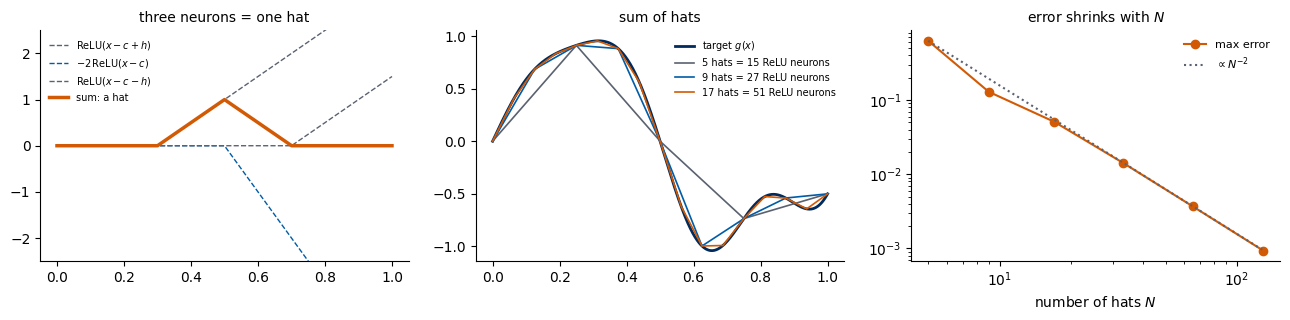

max error: {5: 0.6284, 9: 0.1291, 17: 0.0508, 33: 0.0143, 65: 0.0037, 129: 0.0009}   slope -1.95


In [3]:
relu = lambda z: np.maximum(0.0, z)
g = lambda x: np.sin(2 * np.pi * x) + 0.5 * np.cos(5 * np.pi * x) * x
xs = np.linspace(0, 1, 2001)

def hat_network(n_hats):
    c = np.linspace(0, 1, n_hats); h = c[1] - c[0]
    hats = (relu(xs[:, None] - c + h) - 2 * relu(xs[:, None] - c) + relu(xs[:, None] - c - h)) / h
    return hats @ g(c), hats

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
c0, h0 = 0.5, 0.2
for k, (shift, w, lab) in enumerate([(-h0, 1, "$\\mathrm{ReLU}(x-c+h)$"), (0, -2, "$-2\\,\\mathrm{ReLU}(x-c)$"), (h0, 1, "$\\mathrm{ReLU}(x-c-h)$")]):
    ax[0].plot(xs, w * relu(xs - c0 - shift) / h0, "--", lw=1, color=[UJGray, UJBlue, UJGray][k], label=lab)
hat = (relu(xs - c0 + h0) - 2 * relu(xs - c0) + relu(xs - c0 - h0)) / h0
ax[0].plot(xs, hat, color=DSOrange, lw=2.5, label="sum: a hat")
ax[0].set_ylim(-2.5, 2.5); ax[0].legend(frameon=False, fontsize=7); ax[0].set_title("three neurons = one hat", fontsize=10)

ax[1].plot(xs, g(xs), color=UJNavy, lw=2, label="target $g(x)$")
for n, col in [(5, UJGray), (9, UJBlue), (17, DSOrange)]:
    f, _ = hat_network(n)
    ax[1].plot(xs, f, color=col, lw=1.2, label=f"{n} hats = {3 * n} ReLU neurons")
ax[1].legend(frameon=False, fontsize=7); ax[1].set_title("sum of hats", fontsize=10)

ns = np.array([5, 9, 17, 33, 65, 129])
errs = np.array([np.abs(hat_network(n)[0] - g(xs)).max() for n in ns])
ax[2].loglog(ns, errs, "o-", color=DSOrange, label="max error")
ax[2].loglog(ns, errs[0] * (ns / ns[0]) ** -2.0, ":", color=UJGray, label="$\\propto N^{-2}$")
ax[2].set_xlabel("number of hats $N$"); ax[2].legend(frameon=False, fontsize=8); ax[2].set_title("error shrinks with $N$", fontsize=10)
fig.tight_layout(); savefig(fig, "gen_uat_relu_hats.png"); plt.show()
slope = np.polyfit(np.log(ns), np.log(errs), 1)[0]
print("max error:", dict(zip(ns.tolist(), np.round(errs, 4).tolist())), f"  slope {slope:.2f}")
NUMBERS.update(hat_errors={int(n): float(e) for n, e in zip(ns, np.round(errs, 4))}, hat_slope=round(float(slope), 2))

## 3. A sigmoid becomes a step

For a large weight $w$, $\sigma(w(x-b))$ with the logistic $\sigma$ is almost a step at $x=b$. The difference of two such steps is a
**bar** on $[b_1,b_2]$, and a sum of bars with heights $g$ at the bar centres approximates $g$ like a histogram. This is the picture behind
Cybenko's proof for sigmoidal activations (and the visual argument in Nielsen's book).

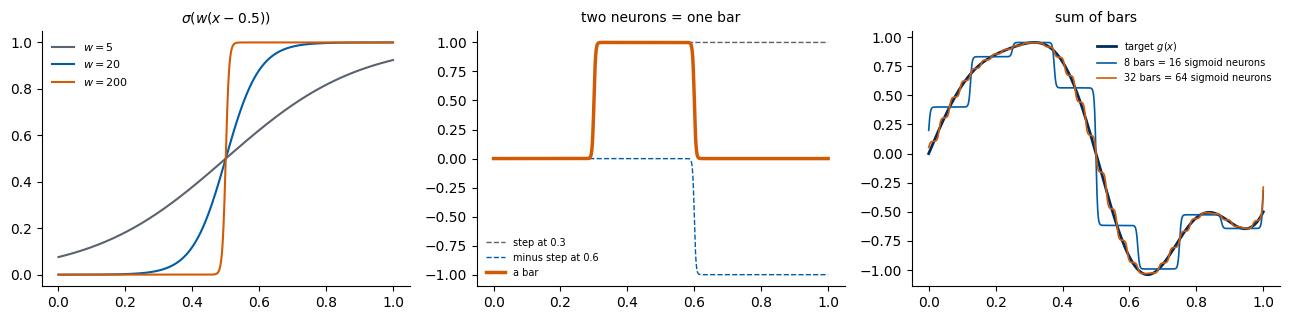

In [4]:
sig = lambda z: 1 / (1 + np.exp(-np.clip(z, -60, 60)))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for w, col in [(5, UJGray), (20, UJBlue), (200, DSOrange)]:
    ax[0].plot(xs, sig(w * (xs - 0.5)), color=col, label=f"$w={w}$")
ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("$\\sigma(w(x-0.5))$", fontsize=10)
w = 400
ax[1].plot(xs, sig(w * (xs - 0.3)), "--", color=UJGray, lw=1, label="step at 0.3")
ax[1].plot(xs, -sig(w * (xs - 0.6)), "--", color=UJBlue, lw=1, label="minus step at 0.6")
ax[1].plot(xs, sig(w * (xs - 0.3)) - sig(w * (xs - 0.6)), color=DSOrange, lw=2.5, label="a bar")
ax[1].legend(frameon=False, fontsize=7); ax[1].set_title("two neurons = one bar", fontsize=10)
ax[2].plot(xs, g(xs), color=UJNavy, lw=2, label="target $g(x)$")
for n, col in [(8, UJBlue), (32, DSOrange)]:
    e = np.linspace(0, 1, n + 1); mid = 0.5 * (e[1:] + e[:-1])
    f = sum(g(m) * (sig(w * (xs - a)) - sig(w * (xs - b))) for m, a, b in zip(mid, e[:-1], e[1:]))
    ax[2].plot(xs, f, color=col, lw=1.2, label=f"{n} bars = {2 * n} sigmoid neurons")
ax[2].legend(frameon=False, fontsize=7); ax[2].set_title("sum of bars", fontsize=10)
fig.tight_layout(); savefig(fig, "gen_uat_sigmoid_steps.png"); plt.show()

## Content and limits of the theorem

* **Says:** for any continuous $g$ on a compact set and any $\epsilon>0$ there is a one-hidden-layer network with
  $\sup_K|f-g|<\epsilon$, for every activation that is not a polynomial.
* **Does not say:** how many neurons are needed (our constructions need more and more as $\epsilon\to0$, and in $d$ input dimensions a grid of
  hats needs a number of neurons growing exponentially with $d$), nor how to find the weights: in practice we train by gradient descent,
  and a good fit on the training points is not a guarantee between them.

> **Try it.** Replace ReLU by $\sigma(z)=z^2$ in Section 1. The network is now nonlinear but polynomial; what does the boundary look like,
> and why does the theorem exclude polynomial activations?

### References
* G. Cybenko, *Approximation by superpositions of a sigmoidal function*, Math. Control Signals Systems **2**, 303 (1989), [doi:10.1007/BF02551274](https://doi.org/10.1007/BF02551274)
* K. Hornik, M. Stinchcombe, H. White, *Multilayer feedforward networks are universal approximators*, Neural Networks **2**, 359 (1989), [doi:10.1016/0893-6080(89)90020-8](https://doi.org/10.1016/0893-6080(89)90020-8)
* M. Leshno, V. Ya. Lin, A. Pinkus, S. Schocken, *Multilayer feedforward networks with a nonpolynomial activation function can approximate any function*, Neural Networks **6**, 861 (1993), [doi:10.1016/S0893-6080(05)80131-5](https://doi.org/10.1016/S0893-6080(05)80131-5)
* M. Nielsen, *Neural Networks and Deep Learning*, chapter 4, [A visual proof that neural nets can compute any function](https://neuralnetworksanddeeplearning.com/chap4.html)

In [5]:
import json
with open(f"{FIG}/numbers_uat.json", "w") as f:
    json.dump(NUMBERS, f, indent=1)
print(NUMBERS)

{'acc_linear': 0.87, 'acc_relu': 1.0, 'hat_errors': {5: 0.6284, 9: 0.1291, 17: 0.0508, 33: 0.0143, 65: 0.0037, 129: 0.0009}, 'hat_slope': -1.95}
